### 1.Bu Projenin Amacı:
Bu proje, bireysel bir hanehalkının elektrik gücü tüketim verilerini analiz ederek enerji tüketim alışkanlıklarını anlamayı ve tüketimdeki anomalileri tespit etmeyi amaçlamaktadır. Ayrıca, alt ölçüm cihazlarının enerji kullanımını inceleyerek enerji yönetimi ve tasarrufu için önerilerde bulunmayı hedefler.

### 2. Veri Seti Tanıtımı

* Veri Kaynağı: UCI Machine Learning Repository
* Veri Seti Adı: Individual Household Electric Power Consumption
* Özellikler:
    * Zaman ve Tarih Bilgisi: Elektrik tüketiminin hangi zaman dilimlerinde yoğun olduğunu analiz etmek için.
    * Global Active Power (kW): Hane genelindeki elektrik tüketiminin dakikalık ortalaması.
    * Global Reactive Power (kW): Reaktif güç tüketimi (indüktif veya kapasitif yükler nedeniyle harcanan enerji).
    * Voltage (V): Hane halkı elektrik voltajı.
    * Global Intensity (A): Akım yoğunluğu (ampere cinsinden).
    * Alt Ölçümler (Sub Metering):
        * Sub_metering_1: Mutfak cihazları (örneğin, mikrodalga, fırın).
        * Sub_metering_2: Çamaşır odası cihazları (örneğin, çamaşır makinesi, kurutucu).
        * Sub_metering_3: Su ısıtıcı ve klima gibi cihazlar.


### Proje Süreci
#### Veri Yükleme ve Temizleme
* Python’da pandas ve numpy kullanılarak veri setinin işlenmesi.
* Eksik değerlerin doldurulması ve veri formatlarının uygun hale getirilmesi.
#### Keşifsel Veri Analizi (EDA):
* Histogramlar ile veri dağılımının incelenmesi.
* Scatter plot ve korelasyon analizleriyle değişkenler arası ilişkilerin incelenmesi.
#### Detaylı Enerji Analizi:
* Alt ölçüm cihazlarının enerji tüketim desenlerini incelemek.
* Zaman serisi grafikleriyle tüketimin zamana göre değişimini analiz etmek.
#### Anomali ve Aşırı Uç Analizi:
* Box plot’lar ve istatistiksel yöntemlerle aşırı uçların tespit edilmesi.
#### Sonuçlar ve Öneriler:
* Enerji tüketimi ile ilgili bulguların raporlanması.
* Enerji tasarrufu için öneriler geliştirilmesi.


### 3. Proje Planı
#### 1.Veri Setini Yüklemek ve İncelemek
öncelikle bireysel evlerin elektrik enerji kullanımına ait veri setini yükleyelim ve üzerine temel analizler yapalım


In [1]:
import pandas as pd
df=pd.read_csv("C:/Users/omerr/OneDrive/Masaüstü/ytu/python_ders/household_power_consumption_hourly.csv",
               sep=",",
               na_values=["?"],
               low_memory=False)

print(df.head())
print(df.info())
print(df.describe())


                  Date  Global_active_power  Global_reactive_power  \
0  2006-12-16 17:00:00             4.222889               0.229000   
1  2006-12-16 18:00:00             3.632200               0.080033   
2  2006-12-16 19:00:00             3.400233               0.085233   
3  2006-12-16 20:00:00             3.268567               0.075100   
4  2006-12-16 21:00:00             3.056467               0.076667   

      Voltage  Global_intensity  Sub_metering_1  Sub_metering_2  \
0  234.643889         18.100000             0.0        0.527778   
1  234.580167         15.600000             0.0        6.716667   
2  233.232500         14.503333             0.0        1.433333   
3  234.071500         13.916667             0.0        0.000000   
4  237.158667         13.046667             0.0        0.416667   

   Sub_metering_3  
0       16.861111  
1       16.866667  
2       16.683333  
3       16.783333  
4       17.216667  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34589 

### 2. Veri Temizleme ve Ön işleme
Veri setinde eksik değerler, yanlış veriler veya gereksiz sütunlar olabilir. Bu adımda, veriyi analiz için uygun hale getireceğiz.

* Eksik değerlerin tespiti ve işlenmesi.
* İlgisiz veya fazla bilgi veren sütunların kaldırılması.
* Kategorik verilerin sayısal verilere dönüştürülmesi
* Tarih sütununun pandas kütüphanesi formatına dönüştürme

In [2]:
print(df.isnull().sum())
df["Global_active_power"].fillna(df["Global_active_power"].mean(),inplace=True)
df["Global_reactive_power"].fillna(df["Global_reactive_power"].mean(),inplace=True)
df["Voltage"].fillna(df["Voltage"].mean(),inplace=True)
df["Global_intensity"].fillna(df["Global_intensity"].mean(),inplace=True)
df["Sub_metering_1"].fillna(df["Sub_metering_1"].mean(),inplace=True)
df["Sub_metering_2"].fillna(df["Sub_metering_2"].mean(),inplace=True)
df["Sub_metering_3"].fillna(df["Sub_metering_3"].mean(),inplace=True)


df.set_index("Date",inplace=True)
df.index=pd.to_datetime(df.index,format="%Y-%m-%d %H:%M:%S")

print(df.head())



Date                       0
Global_active_power      421
Global_reactive_power    421
Voltage                  421
Global_intensity         421
Sub_metering_1           421
Sub_metering_2           421
Sub_metering_3             0
dtype: int64
                     Global_active_power  Global_reactive_power     Voltage  \
Date                                                                          
2006-12-16 17:00:00             4.222889               0.229000  234.643889   
2006-12-16 18:00:00             3.632200               0.080033  234.580167   
2006-12-16 19:00:00             3.400233               0.085233  233.232500   
2006-12-16 20:00:00             3.268567               0.075100  234.071500   
2006-12-16 21:00:00             3.056467               0.076667  237.158667   

                     Global_intensity  Sub_metering_1  Sub_metering_2  \
Date                                                                    
2006-12-16 17:00:00         18.100000             0.0  

C:\Users\omerr\AppData\Local\Temp\ipykernel_3028\3476049928.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Global_active_power"].fillna(df["Global_active_power"].mean(),inplace=True)
C:\Users\omerr\AppData\Local\Temp\ipykernel_3028\3476049928.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values alway

### 3. Veriyi Keşfetmek (Exloratory Data Analysis -EDA)
Verinin genel dağılımını incelemek, veriler arasındaki ilişkileri keşfetmek için istatiksel analizler ver görselleştirmeler yapacağız
* Zaman içinde harcanan aktif gücü inceleyelim.
* Zaman içinde harcanan reaktif gücü inceleyelim
* Zaman içinde harcanan ev de bulunan farklı eşyaların güçlerini inceleyelim
* Alt ölçüm cihazlarının harcadığı enerjilerin birbirine göre karşılaştırması
* Korelasyon ısı haritası
* Histogram grafiği
* Box plot grafiği

#### 1. Zaman Serisinde Global Aktif Güç

C:\Users\omerr\AppData\Local\Temp\ipykernel_3028\3727174320.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df["Monthly_average_global_active_power"]=df["Global_active_power"].resample("M").mean()
C:\Users\omerr\AppData\Local\Temp\ipykernel_3028\3727174320.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_monthly = df.resample("M").mean()


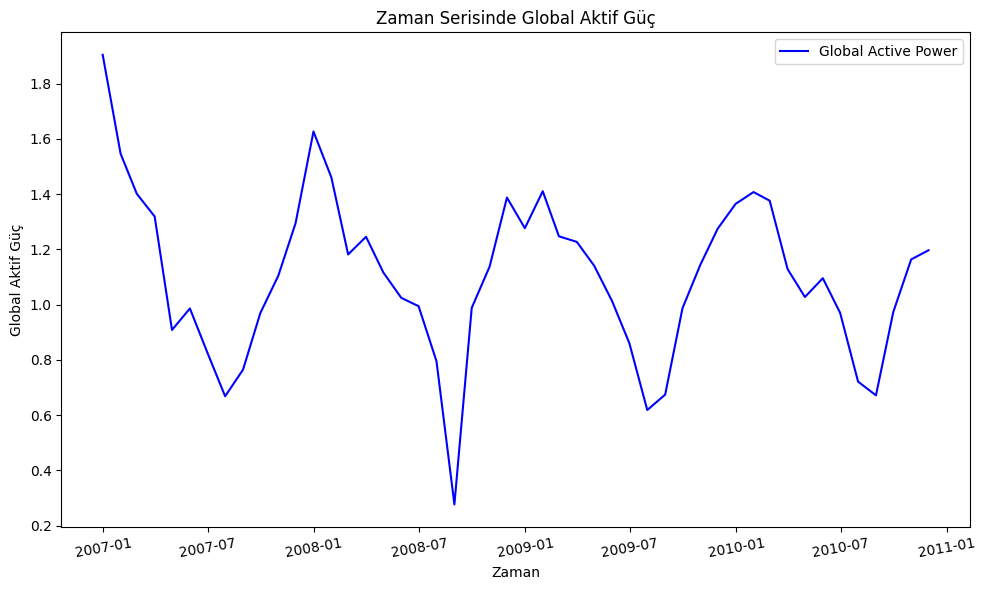

In [3]:
import matplotlib.pyplot as plt
df["Monthly_average_global_active_power"]=df["Global_active_power"].resample("M").mean()
df_monthly = df.resample("M").mean()

plt.figure(figsize=(10,6))
plt.plot(df_monthly.index,df_monthly["Global_active_power"],label="Global Active Power",color="blue")
plt.xlabel("Zaman")
plt.ylabel("Global Aktif Güç")
plt.title("Zaman Serisinde Global Aktif Güç")
plt.xticks(rotation=10)
plt.tight_layout()
plt.legend()

plt.show()

#### 2.Zaman Serisinde Global Reaktif Güç

C:\Users\omerr\AppData\Local\Temp\ipykernel_3028\3838288798.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df["Monthly_average_global_reactive_power"]=df["Global_reactive_power"].resample("M").mean()


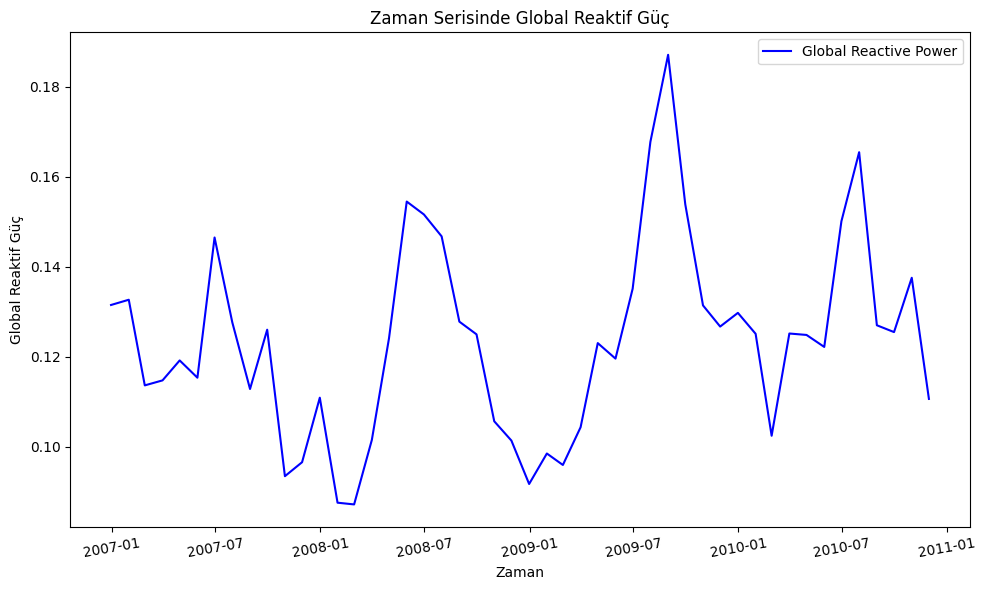

In [4]:
df["Monthly_average_global_reactive_power"]=df["Global_reactive_power"].resample("M").mean()
plt.figure(figsize=(10,6))
plt.plot(df_monthly.index,df_monthly["Global_reactive_power"],label="Global Reactive Power",color="blue")
plt.xlabel("Zaman")
plt.ylabel("Global Reaktif Güç")
plt.title("Zaman Serisinde Global Reaktif Güç")
plt.xticks(rotation=10)
plt.tight_layout()
plt.legend()

plt.show()

#### 3. Zaman serisinde mutfak eşyalarının gücü
 Mutfakta belirli cihazların enerji tüketimini ölçen alt ölçüm değeri. Bu cihazlar genellikle şunlardır:
 * Bulaşık makinesi
 * Fırın
 * Mikrodalga fırım
 Not: ocaklar elektrikli değil gazlıdır.
 ##### Birim: Watt-saat(wh)
 ##### Kullanım Alanı: Çamaşır odasının enerji tüketimini belirlemek ve enerji tasarrufu stratejileri geliştirmek.

C:\Users\omerr\AppData\Local\Temp\ipykernel_3028\1338078427.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df["Monthly_average_sub_metering_1"]=df["Sub_metering_1"].resample("M").mean()


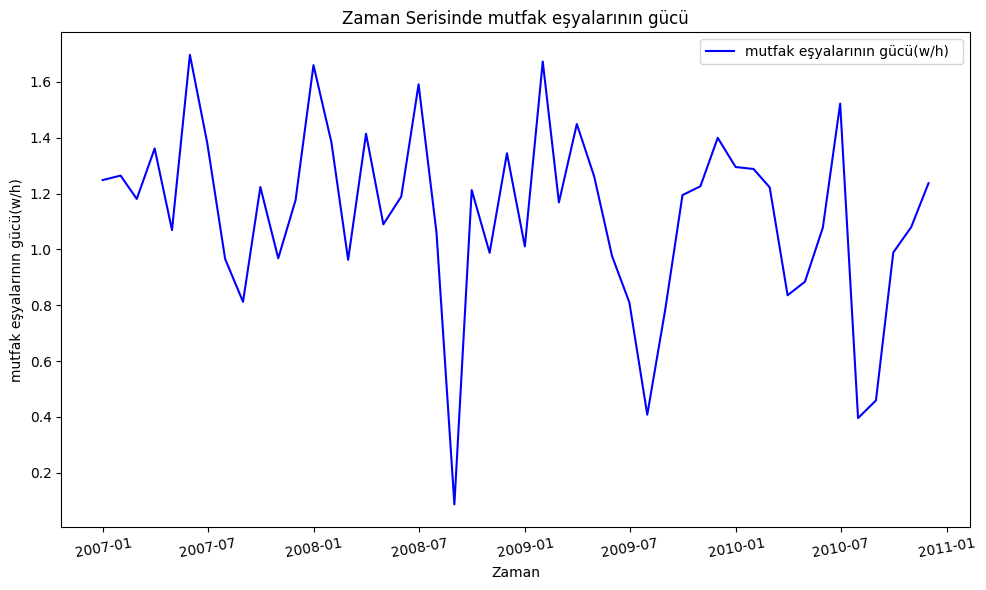

In [5]:
df["Monthly_average_sub_metering_1"]=df["Sub_metering_1"].resample("M").mean()
plt.figure(figsize=(10,6))
plt.plot(df_monthly.index,df_monthly["Sub_metering_1"],label="mutfak eşyalarının gücü(w/h)  ",color="blue")
plt.xlabel("Zaman")
plt.ylabel("mutfak eşyalarının gücü(w/h)")
plt.title("Zaman Serisinde mutfak eşyalarının gücü")
plt.xticks(rotation=10)
plt.tight_layout()
plt.legend()

plt.show()

#### 4. Zaman Serisinde Çamaşır odasının gücü(wh)
Çamaşır odasındaki cihazların enerji tüketimini ölçen alt ölçüm değeri. Bu cihazlar genellikle şunlardır:
* Çamaşır makinesi
* Kurutma makinesi
* Buzdolabı
* aydınlatma
##### Birim: Watt-saat(Wh)
##### Kullanım Alanı: Çamaşır odasının enerji tüketimini belirlemek ve enerji tasarrufu stratejileri geliştirmek.  

C:\Users\omerr\AppData\Local\Temp\ipykernel_3028\1793311376.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df["Monthly_average_sub_metering_2"]=df["Sub_metering_2"].resample("M").mean()


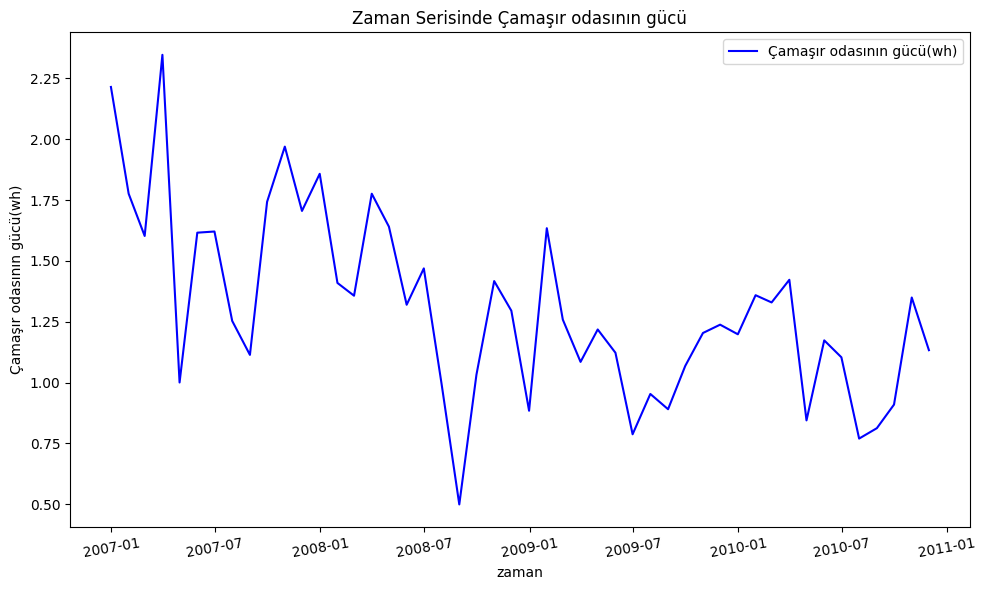

In [6]:
df["Monthly_average_sub_metering_2"]=df["Sub_metering_2"].resample("M").mean()

plt.figure(figsize=(10,6))
plt.plot(df_monthly.index,df_monthly["Sub_metering_2"],label="Çamaşır odasının gücü(wh)",color="blue")
plt.xlabel("zaman")
plt.ylabel("Çamaşır odasının gücü(wh)")
plt.title("Zaman Serisinde Çamaşır odasının gücü")
plt.xticks(rotation=10)
plt.tight_layout()
plt.legend()
plt.show()

#### 5. Bir zaman serisinde elektrikli su ısıtıcı ve ve klimanın harcadığı güç(wh)
* Elektrikli su ısıtıcı ve klimanın enerji tüketimini ölçen alt ölçüm değeri.
##### Birim: Watt-saat(wh)
##### Kullanım Alanı: Isıtma ve soğutma sistemlerinin enerji tüketimini analiz etmek, özellikle enerji yoğun cihazların tüketimlerini optimize etmek.

C:\Users\omerr\AppData\Local\Temp\ipykernel_3028\4099269018.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df["Monthly_average_sub_metering_3"]=df["Sub_metering_3"].resample("M").mean()


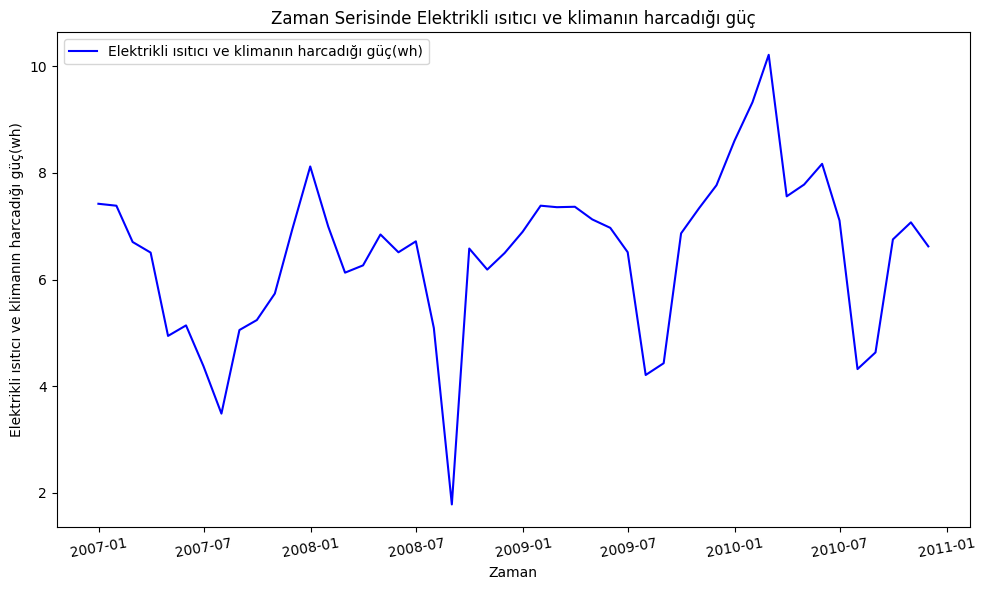

In [7]:

df["Monthly_average_sub_metering_3"]=df["Sub_metering_3"].resample("M").mean()
plt.figure(figsize=(10,6))
plt.plot(df_monthly.index,df_monthly["Sub_metering_3"],label="Elektrikli ısıtıcı ve klimanın harcadığı güç(wh)",color="blue")
plt.xlabel("Zaman")
plt.ylabel("Elektrikli ısıtıcı ve klimanın harcadığı güç(wh)")
plt.title("Zaman Serisinde Elektrikli ısıtıcı ve klimanın harcadığı güç")
plt.xticks(rotation=10)
plt.tight_layout()
plt.legend()
plt.show()

### 6. Alt ölçüm cihazlarının harcadığı enerjilerin birbirine göre karşılaştırması
Neden? Farklı alt ölçüm cihazlarının enerji tüketimlerini karşılaştırarak, hangi cihazların daha fazla enerji tükettiğini görebilirsin.

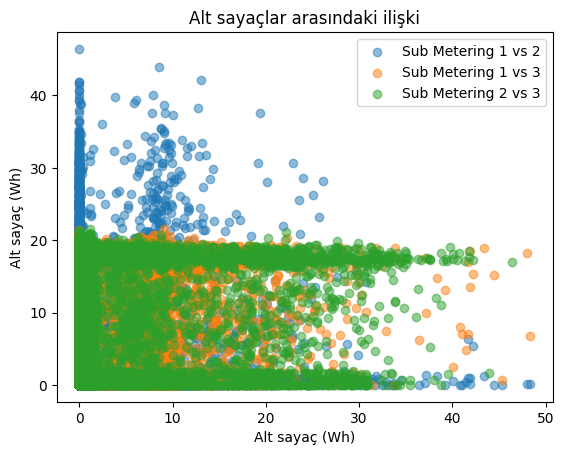

In [8]:
plt.scatter(df['Sub_metering_1'], df['Sub_metering_2'], alpha=0.5, label='Sub Metering 1 vs 2')
plt.scatter(df['Sub_metering_1'], df['Sub_metering_3'], alpha=0.5, label='Sub Metering 1 vs 3')
plt.scatter(df['Sub_metering_2'], df['Sub_metering_3'], alpha=0.5, label='Sub Metering 2 vs 3')
plt.title('Alt sayaçlar arasındaki ilişki')
plt.xlabel('Alt sayaç (Wh)')
plt.ylabel('Alt sayaç (Wh)')
plt.legend()
plt.show()

### 7. Korelasyon ısı haritası
#### Sonuç Analizi
Isı haritasını yorumlarken:

* Pozitif Korelasyon (+1): Bir sütun arttığında diğerinin de arttığını gösterir. Örneğin, global_active_power ve global_intensity arasında pozitif bir ilişki beklenir.
* Negatif Korelasyon (-1): Bir sütun arttığında diğerinin azaldığını gösterir. Örneğin, voltage ve global_intensity arasında negatif bir ilişki olabilir.
* Korelasyon Yok (0): İki değişken arasında ilişki yoktur.


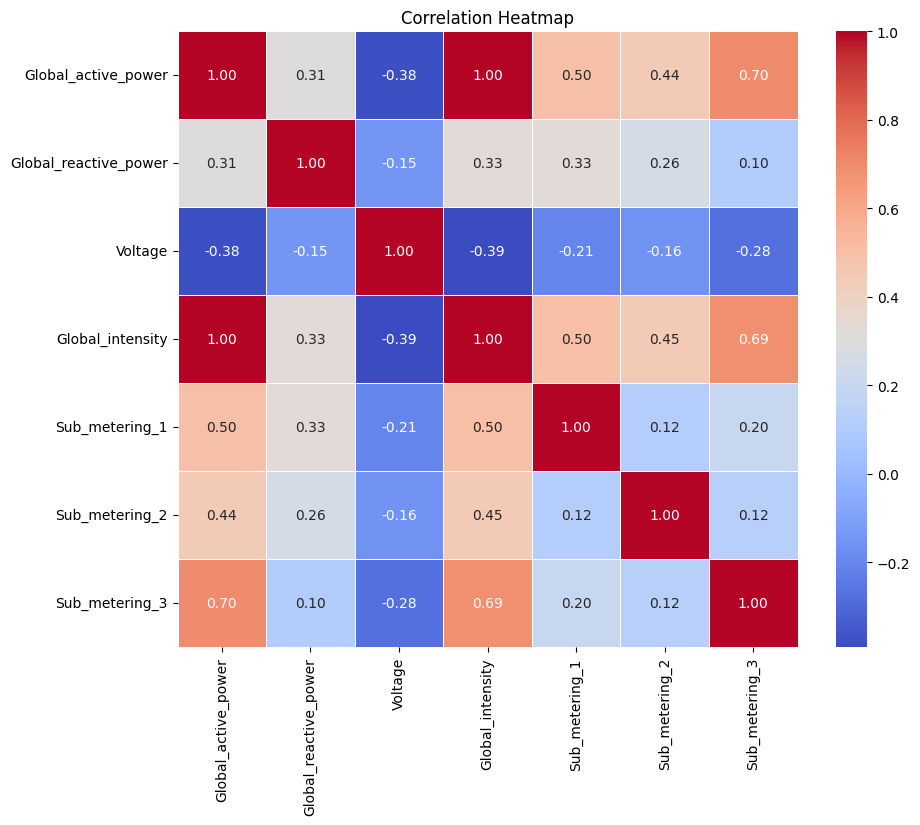

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = ['Global_active_power', 'Global_reactive_power', 'Voltage', 
                'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


correlation_matrix = df[numeric_cols].corr()


plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

### 8. Histogram grafiği
1. Global_active_power (Aktif Güç Tüketimi)
* Dağılım: Genellikle pozitif çarpık (sağa çarpık) bir dağılıma sahip olabilir çünkü çoğu hane düşük enerji tüketimi yaparken, birkaç tanesi yüksek enerji tüketir.
* Ne Anlaşılır?:
    * Ortalama enerji tüketimi yoğunluğu (frekansı en yüksek çubuk).
    * Aşırı uçlardaki yüksek tüketim değerleri, büyük cihazların veya yüksek enerji kullanımına işaret eder.
2. Voltage (Gerilim)
* Dağılım: Simetrik veya dar bir aralıkta yoğunlaşmış olabilir (örneğin, 220V-240V).
* Ne Anlaşılır?:
    * Elektrik sisteminin stabilitesi.
    * Eğer çok geniş bir dağılım varsa, bu sistemdeki dengesizliklere işaret edebilir.
3. Global_intensity (Akım Yoğunluğu)
* Dağılım: Çarpık bir dağılıma sahip olabilir, çünkü çoğu zaman düşük akım yoğunluğu gözlenir.
* Ne Anlaşılır?:
    * Hanelerdeki ortalama akım yoğunluğu.
    * Yüksek değerler, enerji tüketiminin zirve yaptığı zamanlar veya aşırı kullanım anlarını gösterebilir.
4. Sub_metering_1, Sub_metering_2, Sub_metering_3 (Alt Ölçüm Enerji Tüketimi)
* Dağılım: Çoğunlukla düşük değerler gösterir çünkü cihazlar sürekli çalışmaz. Ancak, belirli zamanlarda yüksek enerji tüketimi görülebilir.
* Ne Anlaşılır?:
    * Hangi cihaz grubunun en fazla enerji tükettiği.
    * Seyrek yüksek değerler, belirli cihazların ara sıra yüksek enerji tükettiğini gösterebilir.

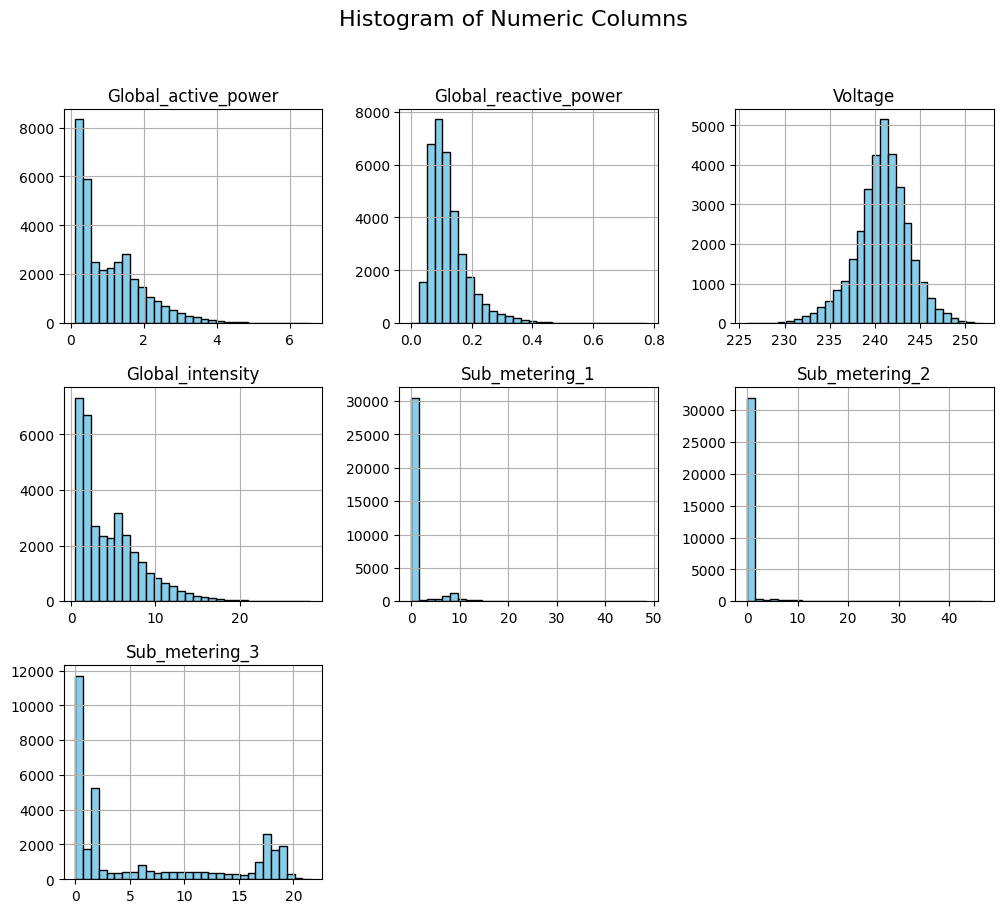

In [10]:
numeric_cols = ['Global_active_power', 'Global_reactive_power', 'Voltage', 
                'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

df[numeric_cols].hist(bins=30, figsize=(12, 10), color='skyblue', edgecolor='black')
plt.suptitle('Histogram of Numeric Columns', fontsize=16)
plt.show()

### 9. Box Plot Grafiği
Box Plot'ta Dikkat Edilmesi Gerekenler
1. Aşırı Uçlar (Outliers): Box plot'ta kutunun dışında kalan noktalar aşırı uçlardır. Bunlar, veri setindeki beklenmeyen veya uç değerleri gösterir.
2. Orta Çizgi: Kutunun içindeki çizgi, medyanı (orta değer) temsil eder.
3. IQR (Interquartile Range): Kutunun uzunluğu, 1. çeyrek (Q1) ile 3. çeyrek (Q3) arasındaki farkı gösterir.

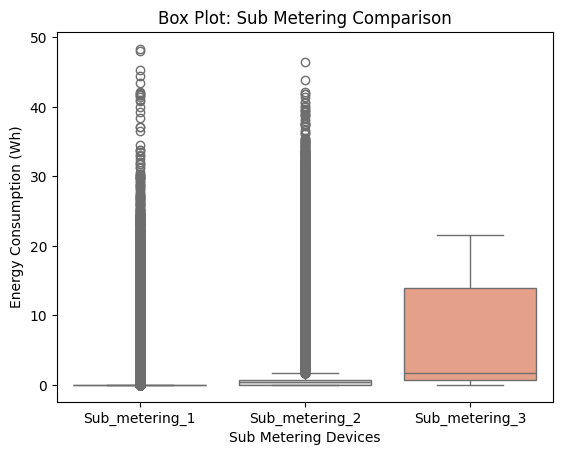

In [11]:
sns.boxplot(data=df[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']], palette='coolwarm')
plt.title('Box Plot: Sub Metering Comparison')
plt.ylabel('Energy Consumption (Wh)')
plt.xlabel('Sub Metering Devices')
plt.show()